In [1]:
from pathlib import Path

import imagecodecs
import imagecodecs.zarr as codecs
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import qim3d
import qim3d.io
import seaborn as sns
import zarr

from comptest.lossless_tests import BASE_JPEGXL_CONFIG
from comptest.zarr import ZarrCompressionConfig, compression_test

%load_ext autoreload
%autoreload 2

In [2]:
imagecodecs.zarr.register_codecs()

In [3]:
DANFIX_201 = Path("/dtu/3d-imaging-center/projects/2026_DANFIX_201")

COMPRESSION_TESTS_DIR = DANFIX_201 / "analysis" / "compression" / "compression_tests"
assert COMPRESSION_TESTS_DIR.is_dir()

DATASETS_DIR = DANFIX_201 / "analysis" / "compression" / "datasets"
assert DATASETS_DIR.is_dir()

VOLUME_COMPRESSION_TESTS_DIR = COMPRESSION_TESTS_DIR / "volume_compression_tests"
assert VOLUME_COMPRESSION_TESTS_DIR.is_dir()

In [4]:
DS_NAME = "Canislupus_CZM_712"

# Load as numpy array
ds = qim3d.io.load(DATASETS_DIR / DS_NAME, contains=DS_NAME + "_")
print(ds.shape)


(1572, 2000, 2000)


In [5]:
# # Rearrange away from planar view to (x, y, view) for compression tests
# ds = einops.rearrange(ds, "view x y -> x y view")
# print(ds.shape)

In [6]:
# DS Tiff file size
tif_total_size = 0
for tif_file in (DATASETS_DIR / DS_NAME).glob("*.tif"):
    tif_total_size += tif_file.stat().st_size

print(tif_total_size, "bytes")
print(tif_total_size / 1e9, "GB")

12576198072 bytes
12.576198072 GB


In [7]:
# from comptest.lossless_tests import C


default_serializer = (
    zarr.codecs.BytesCodec,
    {},
)

chunks_1_channel = (1, 1000, 1000)  # 16-bit * 1 * 1000 * 1000 = 2 MB per chunk
chunks_3_channel = (3, 500, 500)  # 16-bit * 3 * 500 * 500 = 1.5 MB per chunk
chunks_4_channel = (4, 500, 500)  # 16-bit * 4 * 500 * 500 = 2 MB per chunk
chunks_131_channel = (131, 100, 100)  # 16-bit * 1 * 131 * 1000 = 2.62 MB per chunk
chunks_big_image_1_channel = (
    1,
    2000,
    2000,
)  # 16-bit * 1 * 2000 * 2000 = 8 MB per chunk
chunks_big_image_5_channel = (
    5,
    2000,
    2000,
)  # 16-bit * 5 * 2000 * 2000 = 40 MB per chunk
chunks_default = (3, 2000, 2000)

CONFIGS = [
    # {
    #     "serializer": C(codecs.Jpegxl, {"level": 5, "effort": 5, "lossless": True}),
    #     "chunks": chunks_big_image_1_channel,
    # },
    # {
    #     "serializer": C(codecs.Png, {}),
    #     "chunks": chunks_big_image_1_channel,
    #     "lossless": True,
    # },
    # ZarrCompressionConfig(
    #     is_lossless=True,
    #     serializer=(
    #         codecs.Png,
    #         {},
    #     ),
    #     chunks=chunks_big_image_1_channel,
    # ),
    # {
    #     "serializer": C(codecs.Jpeg2k, {"level": 0, "reversible": True}),
    #     "chunks": chunks_default,
    # },
    # {
    #     "serializer": C(codecs.Jpegls, {"level": 0}),
    #     "chunks": chunks_default,
    # },
    # {
    #     "serializer": C(codecs.Webp, {"lossless": True, "method": 4}),
    #     "chunks": chunks_default,
    # },
    ZarrCompressionConfig(
        is_lossless=True,
        series="test",
        serializer=(
            codecs.Jpegxl,
            {"effort": 2, "lossless": True} | BASE_JPEGXL_CONFIG,
        ),
        chunks=(1, ..., ...),
    )
]

In [ ]:
# http://localhost:8888/proxy/8787/status

In [8]:
tests = []
for config in CONFIGS:
    print(f"Running compression test for {config}")
    test = compression_test(
        dataset_name=DS_NAME,
        dataset_path=DATASETS_DIR / DS_NAME,
        data=ds,
        config=config,
        baseline=None,
    )

    tests.append(test)

Running compression test for name=None series='test' is_lossless=True chunks=(1, Ellipsis, Ellipsis) filters=None serializer=(<class 'imagecodecs.zarr.Jpegxl'>, {'effort': 2, 'lossless': True, 'level': 5, 'planar': True, 'transfer': <TRANSFER_FUNCTION.LINEAR: 8>, 'photometric': <COLOR_SPACE.GRAY: 1>, 'usecontainer': False}) compressors=None


In [2]:
import zarr
import zarr.storage
from imagecodecs import zarr as codecs

codecs.register_codecs()

dtype = np.uint16
shape = (100, 2000, 2000)

arr = np.random.randint(0, 65536, size=shape, dtype=dtype)

z = zarr.create_array(
    store=zarr.storage.MemoryStore(),
    shape=arr.shape,
    dtype=arr.dtype,
    chunks=(1, 2000, 2000),
    serializer=(codecs.Jpegxl(planar=True, effort=2, lossless=True)),
)

z[:] = arr


ValueError: planar requires at least 3 dimensions

In [ ]:
import asyncio
from dataclasses import dataclass

from zarr.abc.codec import ArrayBytesCodec


@dataclass(frozen=True)
class TestCodec(ArrayBytesCodec):
    is_fixed_size = False

    def _decode_sync(self, chunk_bytes: Buffer, chunk_spec: ArraySpec) -> NDBuffer:
        decoded = imagecodecs.jpegxl_decode(
            chunk_bytes.as_numpy_array(),
            index=self.index,
            keeporientation=self.keeporientation,
            numthreads=self.numthreads,
        )
        return chunk_spec.prototype.nd_buffer.from_numpy_array(
            decoded.reshape(chunk_spec.shape)
        )

    async def _decode_single(
        self, chunk_bytes: Buffer, chunk_spec: ArraySpec
    ) -> NDBuffer:
        return await asyncio.to_thread(self._decode_sync, chunk_bytes, chunk_spec)

    def _encode_sync(
        self, chunk_array: NDBuffer, chunk_spec: ArraySpec
    ) -> Buffer | None:
        a = chunk_array.as_numpy_array()
        print(a.shape)
        arr = np.atleast_2d(np.squeeze(chunk_array.as_numpy_array()))
        print(arr.shape)
        encoded = imagecodecs.jpegxl_encode(
            arr,
            level=self.level,
            effort=self.effort,
            distance=self.distance,
            lossless=self.lossless,
            decodingspeed=self.decodingspeed,
            bitspersample=self.bitspersample,
            photometric=self.photometric,
            planar=self.planar,
            primaries=self.primaries,
            transfer=self.transfer,
            usecontainer=self.usecontainer,
            numthreads=self.numthreads,
        )
        return chunk_spec.prototype.buffer.from_bytes(encoded)

    async def _encode_single(
        self, chunk_array: NDBuffer, chunk_spec: ArraySpec
    ) -> Buffer | None:
        return await asyncio.to_thread(self._encode_sync, chunk_array, chunk_spec)

    def compute_encoded_size(
        self, input_byte_length: int, chunk_spec: ArraySpec
    ) -> int:
        raise NotImplementedError


z = zarr.create_array(
    store=zarr.storage.MemoryStore(),
    shape=ds.shape,
    dtype=ds.dtype,
    chunks=(1, 2000, 2000),
    serializer=TestCodec(),
)
z[:] = ds
z.info_complete()

(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)


AttributeError: 'TestCodec' object has no attribute 'level'

(1, 2000, 2000)(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)

(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)


(1, 2000, 2000)(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)

(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000)
(2000, 2000)
(1, 2000, 2000

In [ ]:
np.ascontiguousarray(ds[1, :, :]).shape

(2000, 2000)

In [ ]:
print(test.model_dump_json(fallback=repr, indent=2))

{
  "name": "{\"name\":null,\"is_lossless\":true,\"chunks\":[1,2000,2000],\"filters\":null,\"serializer\":[\"Png\",{}],\"compressors\":null}",
  "id": "{\"name\":null,\"is_lossless\":true,\"chunks\":[1,2000,2000],\"filters\":null,\"serializer\":[\"Png\",{}],\"compressors\":null}",
  "dataset_name": "Canislupus_CZM_712",
  "dataset_path": "/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712",
  "start_dt": "2026-07-26T18:24:36.428099Z",
  "end_dt": "2026-07-26T18:26:19.466404Z",
  "total_time_seconds": 103.038305,
  "config": {
    "name": null,
    "is_lossless": true,
    "chunks": [
      1,
      2000,
      2000
    ],
    "filters": null,
    "serializer": [
      "Png",
      {}
    ],
    "compressors": null
  },
  "baseline_test": null,
  "compress_time_seconds": 103.03371423890349,
  "nbytes": 12576000000,
  "nbytes_stored": 9755002661,
  "bitrate": 16.0,
  "bitrate_compressed": 12.410944861323156,
  "compression_ratio": 1.289184681

In [ ]:
print(test.model_dump_json(indent=2))
# test.array_info

PydanticSerializationError: Unable to serialize unknown type: <class 'numpy.uint16'>

In [ ]:
repr(test.array_info["_fill_value"])

'np.uint16(0)'

In [ ]:
config.get_name()

'{"name":null,"is_lossless":true,"chunks":[1,2000,2000],"filters":null,"serializer":["Png",{}],"compressors":null}'

In [ ]:
from collections.abc import Mapping, Sequence


def flatten(data, prefix: str = "", sep: str = "__") -> dict:
    flattened = {}

    if isinstance(data, Mapping):
        for key, value in data.items():
            column = f"{prefix}{sep}{key}" if prefix else str(key)
            flattened.update(flatten(value, column, sep))

    elif isinstance(data, Sequence) and not isinstance(data, (str, bytes)):
        for index, value in enumerate(data):
            column = f"{prefix}[{index}]"
            flattened.update(flatten(value, column, sep))

    else:
        flattened[prefix] = data

    return flattened


rows = []
for spec in tests:
    row = spec.model_dump()
    config = row.pop("config")
    rows.append({**row, **flatten(config)})


df = pl.DataFrame(rows)
df


name,id,dataset_name,dataset_path,start_dt,end_dt,total_time_seconds,baseline_test,compress_time_seconds,nbytes,nbytes_stored,bitrate,bitrate_compressed,compression_ratio,lossless,array_info,is_lossless,chunks[0],chunks[1],chunks[2],filters,serializer[0],compressors
null,str,str,object,"datetime[μs, UTC]","datetime[μs, UTC]",f64,null,f64,i64,i64,f64,f64,f64,bool,struct[16],bool,i64,i64,i64,null,object,null
null,"""{""name"":null,""is_lossless"":tru…","""Canislupus_CZM_712""",/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712,2026-07-26 18:07:28.938806 UTC,2026-07-26 18:09:11.576567 UTC,102.637761,null,102.63385,12576000000,9755002661,16.0,12.410945,1.289185,true,"{""Array"",3,{""little""},0,[1572, 2000, 2000],null,[1, 2000, 2000],""C"",false,""MemoryStore"",[],{null,null,null},[{0,false}],12576000000,9755002661,1572}",true,1,2000,2000,null,<class 'imagecodecs.zarr.Png'>,null


2026-07-26 20:09:14,392 - matplotlib.pyplot - DEBUG - Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-07-26 20:09:14,393 - matplotlib.pyplot - DEBUG - Loaded backend module://matplotlib_inline.backend_inline version unknown.
2026-07-26 20:09:14,417 - matplotlib.font_manager - DEBUG - findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
2026-07-26 20:09:14,417 - matplotlib.font_manager - DEBUG - findfont: score(FontEntry(fname='/zhome/1a/a/219376/Code/qim-naturarv3d-compression/.pixi/envs/default/lib/python3.14/site-packages/matplotlib/mpl-data/fonts/ttf/cmss10.ttf', index=0, name='cmss10', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-07-26 20:09:14,418 - matplotlib.font_manager - DEBUG - findfont: score(FontEntry(fname='/zhome/1a/a/219376/Code/qim-naturarv3d-compression/.pixi/envs/default/lib/python3.14/site-packages/matplotlib/mpl-data/fonts/ttf/STIXGeneralIta

2026-07-26 20:09:14,422 - matplotlib.font_manager - DEBUG - findfont: score(FontEntry(fname='/zhome/1a/a/219376/Code/qim-naturarv3d-compression/.pixi/envs/default/lib/python3.14/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif-Bold.ttf', index=0, name='DejaVu Serif', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335
2026-07-26 20:09:14,422 - matplotlib.font_manager - DEBUG - findfont: score(FontEntry(fname='/zhome/1a/a/219376/Code/qim-naturarv3d-compression/.pixi/envs/default/lib/python3.14/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSansMono.ttf', index=0, name='DejaVu Sans Mono', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
2026-07-26 20:09:14,422 - matplotlib.font_manager - DEBUG - findfont: score(FontEntry(fname='/zhome/1a/a/219376/Code/qim-naturarv3d-compression/.pixi/envs/default/lib/python3.14/site-packages/matplotlib/mpl-data/fonts/ttf/cmtt10.ttf', index=0, name='cmtt10', style='n

<Figure size 640x480 with 0 Axes>

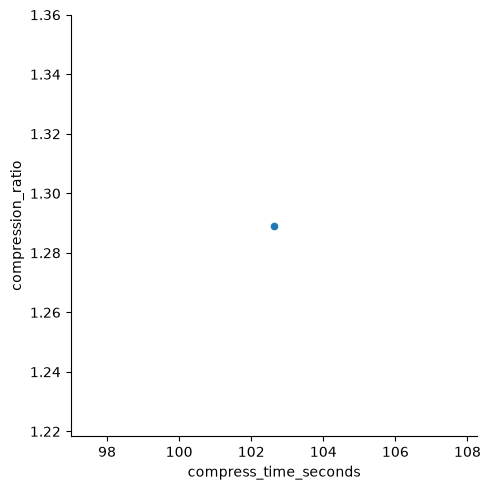

<Figure size 640x480 with 0 Axes>

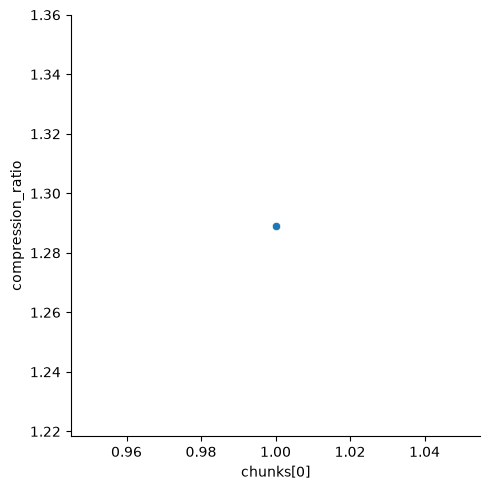

In [ ]:
plt.figure()
sns.relplot(data=df, x="compress_time_seconds", y="compression_ratio")

plt.figure()
sns.relplot(data=df, x="chunks[0]", y="compression_ratio")